<a href="https://colab.research.google.com/github/aashish7542/ai-learning/blob/main/phase-0-foundations/python/Phase_0_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Loss Function and Gradients
$$A_{\text{new}} = A - \alpha \frac{2}{n} X^T (XA - B)$$

B the label
X is the features, with extra 1's column
A is initial parameter (gets iterated)
alpha is the learning rate
n is the number of labels/rows of A


here, we are assuming linear model $y = mx + b$ ==> So, A is [m,c]



In [1]:
import numpy as np

X = np.array([
    [1, 1],
    [1, 2],
    [1, 3],
    [1, 4]
])

B = np.array([2, 4, 6, 8])

A = np.zeros(2) # initialised parameters (gets iterated upon)
alpha = 0.01 # learning rate

In [2]:
def gradient_step(X, B, A, alpha):
    n = len(B)
    gradient = (2 / n) * (X.T @ (X @ A - B))
    A_new = A - alpha * gradient
    return A_new

for step in range(1000):
    A = gradient_step(X, B, A, alpha)

print(A)

[0.03040452 1.98965876]


#2. Learning rates and convergence
We are testing for two different learning rates and check how they compare

In [3]:
alpha_ = [0.1,0.2]

for alpha in alpha_:
    A = np.zeros(2)

    for step in range(50):
        A = gradient_step(X, B, A, alpha)

    mse = np.mean((X @ A - B) ** 2)

    print(f"Alpha: {alpha}")
    print(f"Parameters: {A}")
    print(f"MSE: {mse:.6f}\n")

Alpha: 0.1
Parameters: [0.13337533 1.95463612]
MSE: 0.002971

Alpha: 0.2
Parameters: [-1.76623441e+18 -5.19294455e+18]
MSE: 251229419127653311379279862277519441920.000000



#3. Stochastic Gradient Descent
$$ \boxed{\nabla L_i = 2x_i(x_i^T A - y_i)} $$

In [4]:
def sgd_step(X, B, A, alpha):
    # Select one random training example
    # Calculate its gradient
    # Update parameters
    i = np.random.randint(len(B))
    x_i = X[i]
    y_i = B[i]
    gradient = 2 * x_i * (x_i @ A - y_i)
    A_new = A - alpha * gradient
    return A_new

np.random.seed(42)

for alpha in [0.001, 0.01]:
    A = np.zeros(2)

    for step in range(1000):
        A = sgd_step(X, B, A, alpha)

    mse = np.mean((X @ A - B) ** 2)
    print(f"Alpha: {alpha}, A: {A}, MSE: {mse:.6f}")

Alpha: 0.001, A: [0.43310314 1.86106245], MSE: 0.031484
Alpha: 0.01, A: [0.031935   1.98704419], MSE: 0.000210


#4. Mini Batch Gradient Descent
$$\nabla L = \frac{2}{m} X_{\text{batch}}^T (X_{\text{batch}}A - B_{\text{batch}})
$$

In [5]:
def minibatch_step(X, B, A, alpha, batch_size=2):
    indices = np.random.choice(
        len(B), size=batch_size, replace=False
        )

    X_batch = X[indices]
    B_batch = B[indices]

    gradient = (2/batch_size) * (X_batch.T @ (X_batch @ A - B_batch))
    A_new = A - alpha * gradient

    return A_new

for alpha in [0.01,0.1]:
    A = np.zeros(2)

    for step in range(1000):
        A = minibatch_step(X, B, A, alpha)

    mse = np.mean((X @ A - B) ** 2)
    print(f"Alpha: {alpha}, A: {A}, MSE: {mse:.6f}")

Alpha: 0.01, A: [0.0321103  1.98931746], MSE: 0.000172
Alpha: 0.1, A: [9.81172552e-15 2.00000000e+00], MSE: 0.000000


#5. Visualizing and Debugging Optimization

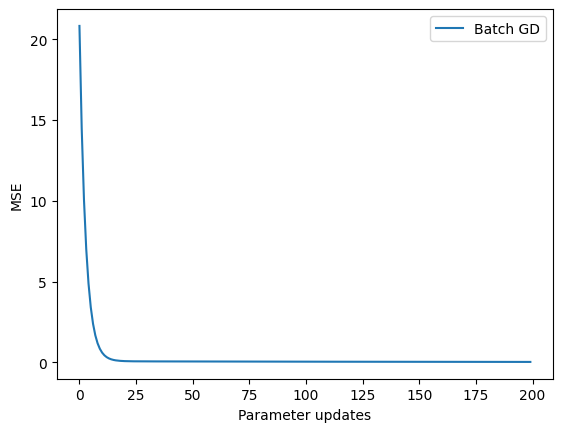

In [6]:
# Normal gradient Descent

import matplotlib.pyplot as plt

A = np.zeros(2)
alpha = 0.01
steps = 200

losses_batch = []

for step in range(steps):
    A = gradient_step(X, B, A, alpha)
    mse = np.mean((X @ A - B) ** 2)
    losses_batch.append(mse)

plt.plot(losses_batch, label="Batch GD")
plt.xlabel("Parameter updates")
plt.ylabel("MSE")
plt.legend()
plt.show()

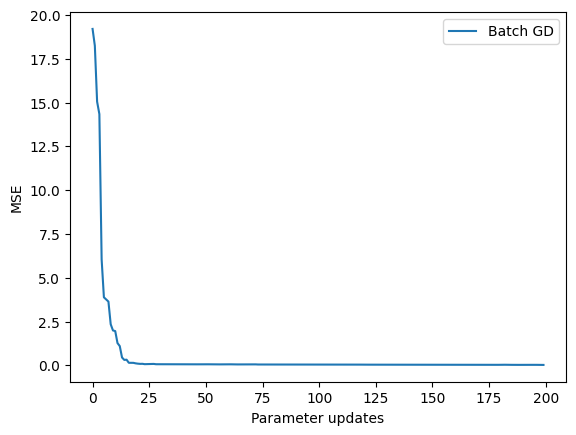

In [7]:
#SGD
import matplotlib.pyplot as plt

A = np.zeros(2)
alpha = 0.01
steps = 200
losses_batch = []
for step in range(steps):
    A = sgd_step(X, B, A, alpha)
    mse = np.mean((X @ A - B) ** 2)
    losses_batch.append(mse)
plt.plot(losses_batch, label="Batch GD")
plt.xlabel("Parameter updates")
plt.ylabel("MSE")
plt.legend()
plt.show()


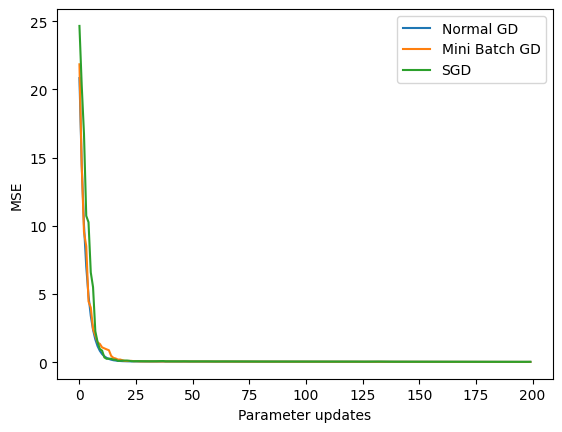

In [8]:
#Mini Batch
#Actually, I combined all three in this one
import matplotlib.pyplot as plt

A_n = np.zeros(2)
A_sgd = np.zeros(2)
A_m = np.zeros(2)
alpha = 0.01
steps = 200
losses_batch_n = [] #n is normal gradient descent
losses_batch_sgd = [] #sgd is what it is
losses_batch_m = []  # m is minibatch
for step in range(steps):
    A_m  = minibatch_step(X, B, A_m, alpha)
    A_n = gradient_step(X, B, A_n, alpha)
    A_sgd = sgd_step(X, B, A_sgd, alpha)
    mse_n = np.mean((X @ A_n - B) ** 2)
    mse_m = np.mean((X @ A_m - B) ** 2)
    mse_sgd = np.mean((X @ A_sgd - B) ** 2)
    losses_batch_n.append(mse_n)
    losses_batch_m.append(mse_m)
    losses_batch_sgd.append(mse_sgd)

plt.plot(losses_batch_n, label="Normal GD")
plt.plot(losses_batch_m, label="Mini Batch GD")
plt.plot(losses_batch_sgd, label="SGD")
plt.xlabel("Parameter updates")
plt.ylabel("MSE")
plt.legend()
plt.show()


#6. Numerical Gradient Checking

Before finishing optimization, let's learn one extremely useful debugging technique.

Suppose you've implemented a gradient, but you're unsure whether it's mathematically correct.

You can independently approximate each partial derivative using:
$$\frac{\partial L}{\partial A_j} \approx \frac{L(A + \epsilon e_j) - L(A - \epsilon e_j)}{2\epsilon}
$$

where \(e_j\) changes only parameter \(j\).

This is called numerical gradient checking. It's especially valuable when implementing neural networks from scratch.

In [9]:
A = np.array([0.5, 1.5])
eps = 1e-5

def loss(A):
    return np.mean((X @ A - B) ** 2)

analytic_grad = (2 / len(B)) * X.T @ (X @ A - B)